In [1]:
import tensorflow as tf
import tensorflow.keras as k
import matplotlib.pyplot as plt
import numpy as np

In [3]:
path_train = './seg/seg_train'
path_test = './seg/seg_test'
batch_size = 5000
image_size = (150,150)


test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    path_test ,
    shuffle = False ,
    batch_size = batch_size ,
    image_size = image_size
)

Found 3000 files belonging to 6 classes.


In [4]:
X_test_list = []
y_test_list = []
for imge , lable in test_ds:
    X_test_list.append(imge.numpy())
    y_test_list.append(lable.numpy())

class_name = test_ds.class_names
y_true = np.concatenate(y_test_list, axis=0)

In [5]:
model_4 = k.models.load_model('./model_4layer.keras')
model_3 = k.models.load_model('./model_3layer.keras')



In [6]:
from sklearn.metrics import classification_report
y_pred_4 = np.argmax(model_4.predict(X_test_list) , axis=1)



c:\Users\user\miniconda3\envs\tf_env\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_3
Received: inputs=('Tensor(shape=(32, 150, 150, 3))',)
  warnings.warn(msg)


93/94 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step

c:\Users\user\miniconda3\envs\tf_env\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_3
Received: inputs=('Tensor(shape=(None, 150, 150, 3))',)
  warnings.warn(msg)


94/94 ━━━━━━━━━━━━━━━━━━━━ 48s 496ms/step


In [16]:
y_pred_3 = np.argmax(model_3.predict(X_test_list) , axis=1)

c:\Users\user\miniconda3\envs\tf_env\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_10
Received: inputs=('Tensor(shape=(32, 150, 150, 3))',)
  warnings.warn(msg)


93/94 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step

c:\Users\user\miniconda3\envs\tf_env\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_10
Received: inputs=('Tensor(shape=(None, 150, 150, 3))',)
  warnings.warn(msg)


94/94 ━━━━━━━━━━━━━━━━━━━━ 19s 186ms/step


In [17]:
print("=======================================")
print("(Model 1): 4 layer ")
print("=======================================")
print(classification_report(y_true, y_pred_4, target_names=class_name))

print("=======================================")
print("(Model 2): 3 layer ")
print("=======================================")
print(classification_report(y_true, y_pred_3, target_names=class_name))


(Model 1): 4 layer 
              precision    recall  f1-score   support

   buildings       0.82      0.84      0.83       437
      forest       0.99      0.94      0.96       474
     glacier       0.86      0.76      0.80       553
    mountain       0.81      0.78      0.79       525
         sea       0.76      0.91      0.83       510
      street       0.88      0.87      0.87       501

    accuracy                           0.85      3000
   macro avg       0.85      0.85      0.85      3000
weighted avg       0.85      0.85      0.85      3000

(Model 2): 3 layer 
              precision    recall  f1-score   support

   buildings       0.68      0.85      0.76       437
      forest       0.95      0.96      0.96       474
     glacier       0.82      0.75      0.78       553
    mountain       0.81      0.71      0.76       525
         sea       0.81      0.77      0.79       510
      street       0.82      0.85      0.84       501

    accuracy                         

In [18]:
history4_dict = np.load('./history_4layer.npy', allow_pickle=True).item()
history3_dict = np.load('./history_3layer.npy', allow_pickle=True).item()
print("✅ تم تحميل ملفات الـ History بنجاح!")


✅ تم تحميل ملفات الـ History بنجاح!


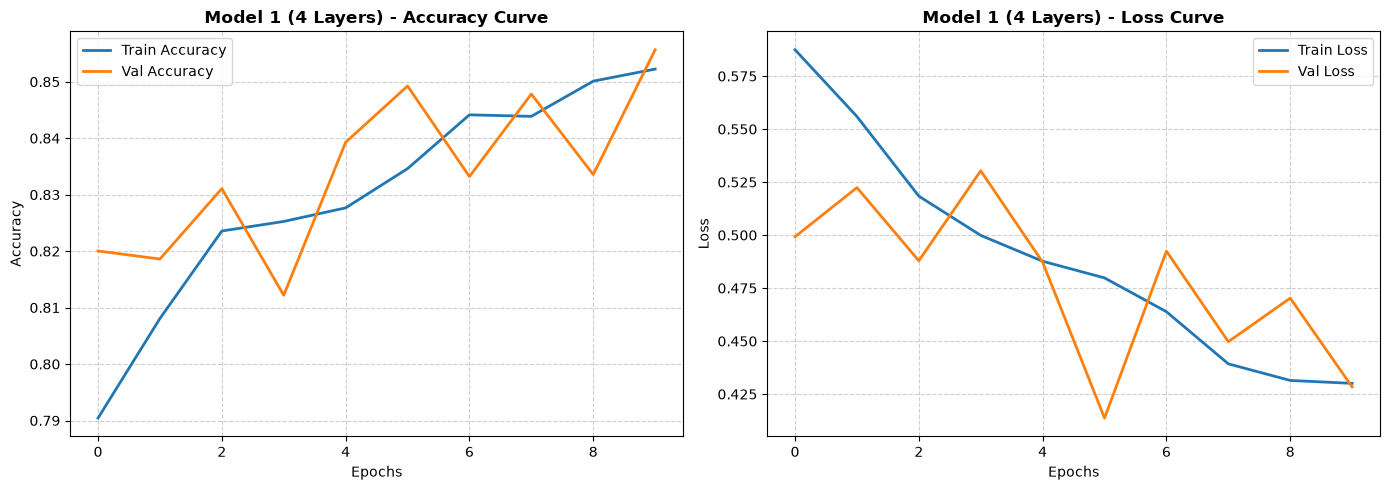

In [19]:
import matplotlib.pyplot as plt

def plot_history_dict(hist_dict, title="Model"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. رسم منحنى الدقة Accuracy
    ax1.plot(hist_dict['accuracy'], label='Train Accuracy', linewidth=2)
    ax1.plot(hist_dict['val_accuracy'], label='Val Accuracy', linewidth=2)
    ax1.set_title(f'{title} - Accuracy Curve', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy')
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend()
    
    # 2. رسم منحنى الخسارة Loss
    ax2.plot(hist_dict['loss'], label='Train Loss', linewidth=2)
    ax2.plot(hist_dict['val_loss'], label='Val Loss', linewidth=2)
    ax2.set_title(f'{title} - Loss Curve', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss')
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

# رسم المنحنيات للنموذج الأول
plot_history_dict(history4_dict, "Model 1 (4 Layers)")

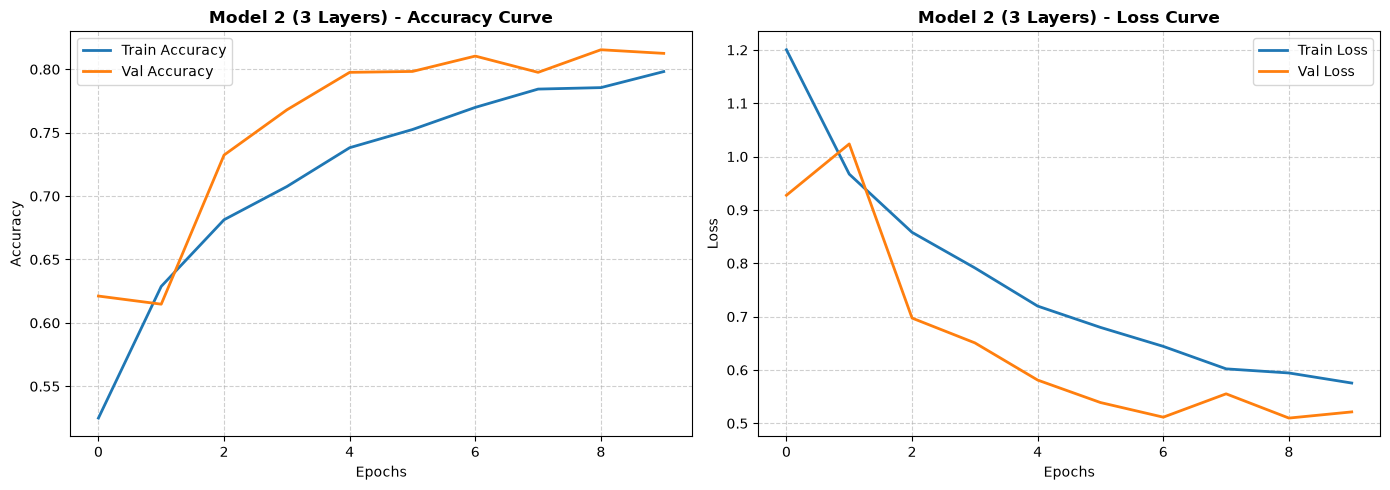

In [20]:
plot_history_dict(history3_dict, "Model 2 (3 Layers)")

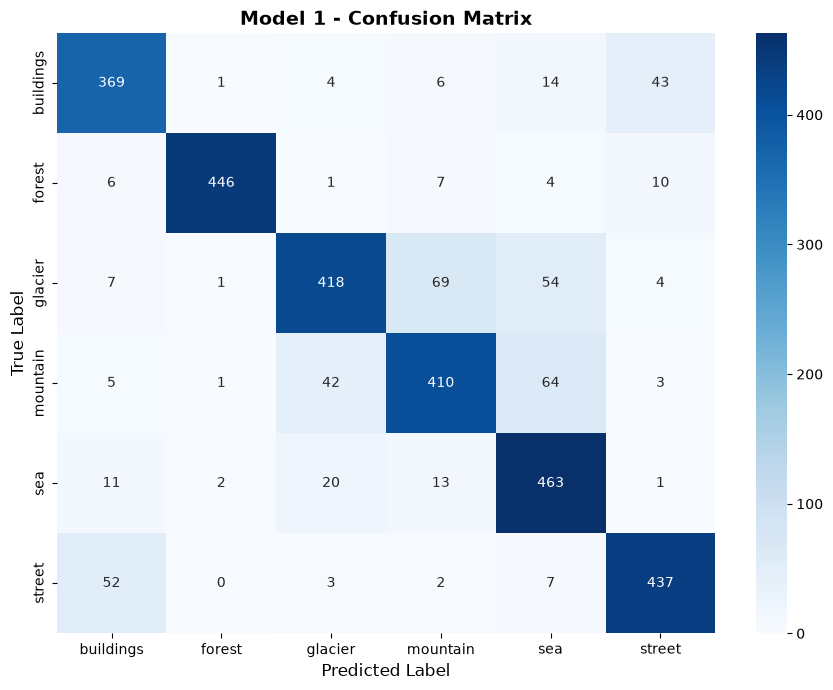

In [21]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred_4)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_ds.class_names,
            yticklabels=test_ds.class_names)

plt.title('Model 1 - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

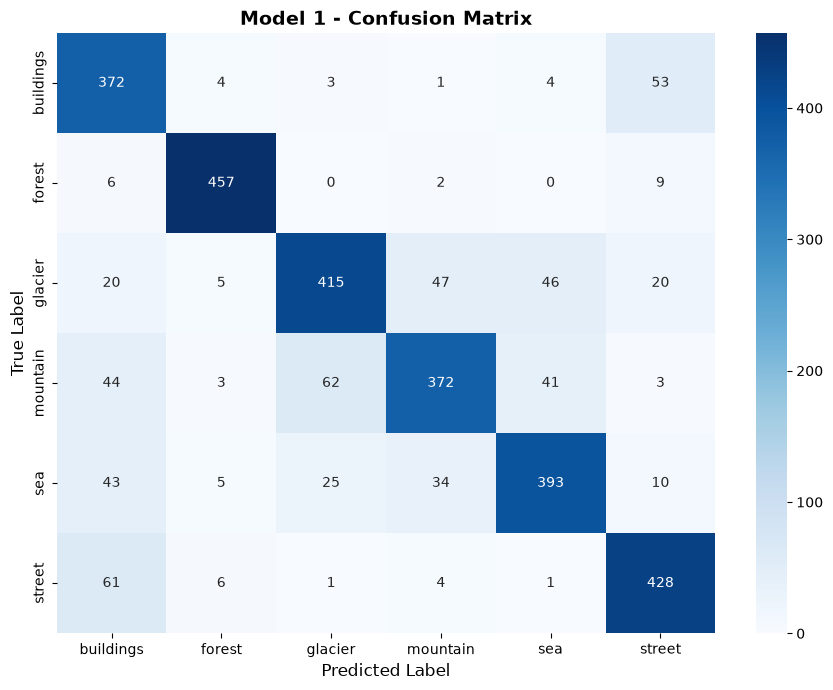

In [22]:

cm = confusion_matrix(y_true, y_pred_3)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_ds.class_names,
            yticklabels=test_ds.class_names)

plt.title('Model 1 - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

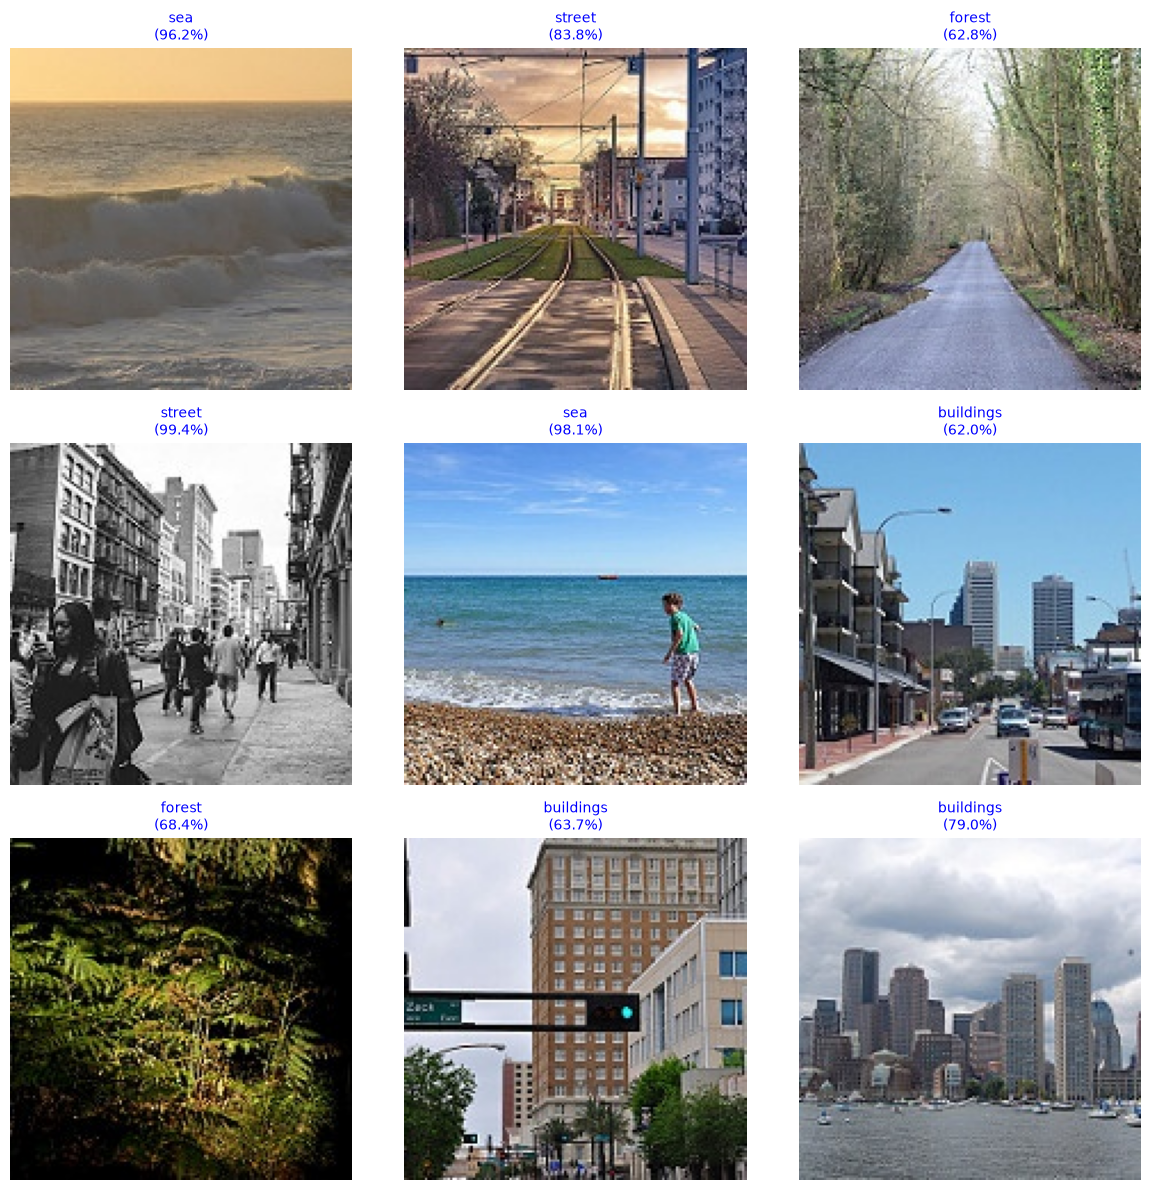

In [40]:
from pathlib import Path
import cv2

folder = Path('./seg_pred/seg_pred')
x = 106
image_paths = list(folder.glob('*.jpg'))[x : x+9]

def expexted9imge(image_paths :list , model):
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    axes = axes.ravel()
    for i, path in enumerate(image_paths):

        img = cv2.imread(str(path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        img_resized = cv2.resize(img, (150, 150)) 
        img_batch = np.expand_dims(img_resized, axis=0)
        
        p = model.predict(img_batch, verbose=0)
        x = np.argmax(p[0])
        label = class_name[x]
        confidence = p.max()
        
        axes[i].imshow(img)
        axes[i].set_title(f"{label}\n({confidence*100:.1f}%)", fontsize=10, color='blue')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
expexted9imge(image_paths , model_4)